### This notebook performs in-silico mutagenesis (ISM) on a gene of interest under a selected condition to identify putative regulatory regions and transcription factor (TF) drivers of gene expression (activators and repressors).

> **Note:** This notebook uses the Araport11 genome annotation.

> **Note:** The analyses generated by this notebook may not be equally reliable for all genes or experimental conditions. To help assess result quality, we report a confidence measure for each gene based on the Pearson correlation coefficient and Spearman correlation coefficient between observed gene expression and model predictions. Higher correlation values indicate better agreement and, consequently, greater confidence in the inferred regulatory insights.

### What this does:
* Mutates each nucleotide in a gene TSS-centered sequence
* Measures impact on predicted expression
* Identifies important positions
* Links mutations to TF binding and ChIP-seq evidence
* Generates visualization tracks

### Action Required: Section 3 (User Input):
* GENE_NAME: The locus ID (e.g., AT2G01980).
* EXPERIMENT_ID: The unique identifier for the expression experiment


# 1. Setup & Imports, Environment & Paths

In [1]:
import pandas as pd
from src.utils import hot_encode_sequence, create_path
import torch
from fastprogress import progress_bar
from src.config import GEPConfig
from src.utils import read_json, get_device
from src.DeepPlant import build_model
import numpy as np
from src.ISM_utils import *
import os
from dotenv import load_dotenv
from scipy.stats import pearsonr,spearmanr
import seaborn as sns
sns.set_theme(style='white')
import h5py

# 1. Load the variables from the .env file
load_dotenv()

# 2. Grab the global path
deep_plant_path = os.getenv("DEEPPLANTPATH")

if not deep_plant_path:
    raise ValueError("DEEPPLANTPATH is missing! Run 'python3 setup_env.py' in the root DeepPlant directory")

load_dotenv()

deep_plant_path = os.getenv("DEEPPLANTPATH")

if not deep_plant_path:
    raise ValueError(
        "DEEPPLANTPATH is not set.\n"
        "Fix:\n"
        "  export DEEPPLANTPATH=/path/to/DeepPlant"
    )

# Paths
json_path = os.path.join(deep_plant_path, "config/config_AT_GEP.json")
model_path = os.path.join(deep_plant_path, "results/GEP_AT/835811/model_26_09_01:18:43.pt") #

gene_df_path = os.path.join(deep_plant_path, "data/arabidopsis/GEP/gene_list.txt")
gex_metadata_path = os.path.join(deep_plant_path, "data/arabidopsis/GEP/AT_GEP_Metadata.tsv")
csp_metadata_path = os.path.join(deep_plant_path, "data/arabidopsis/CSP/AT_CSP_Metadata.csv")
bed_files_path = os.path.join(deep_plant_path, "data/arabidopsis/bed")
meme_path = os.path.join(deep_plant_path, "data/arabidopsis/jaspar/all.meme")
gff_db_path = os.path.join(deep_plant_path, "data/arabidopsis/gff/tair10.62.db")

# 2. Load model and data

In [2]:
device = get_device()

config = GEPConfig(**read_json(json_path))
SEQ_LEN = config.sequence_length
HALF = SEQ_LEN//2
n_feautres = config.n_features[0]
model = build_model(config, new_model=False, task='GEP', model_path=model_path).to(device)

gene_df = pd.read_csv(gene_df_path, sep="\t")
gex_metadata = pd.read_csv(gex_metadata_path, sep="\t")
csp_metadata = pd.read_csv(csp_metadata_path)

h5_gex = h5py.File(os.path.join(deep_plant_path, config.h5_paths[0]))

# Load motif database
motifs_dict = load_meme_database(meme_path)
motifs_dict = get_latest_motifs(motifs_dict)

all_sequences = [seq.decode() for seq in h5_gex["sequences"][...]]
background_freq = nuclt_dict(all_sequences)
pssm_dict_jaspar = get_motifs(motifs_dict, background_freq)

Loading model state
Model state loaded
freeze='none': 248,667,511 / 248,667,511 parameters trainable


# 3. User Inputs

### Select a gene of interest for analysis.
### Below is a list of recommended genes with well-characterized regulatory behavior.
### Refer to data/arabidopsis/GEP/gene_list.txt for the full list of genes
| Gene | Gene name | Stress Induced |
| :--- | :--- | :--- |
| AT5G52310 | RAD29A | General Stress |
| AT5G52300 | RD29B | Cold + drought |
| AT5G25610 | RD22 | Dehydration + Salt + ABA |
| AT4G25470 | CBF2 / DREB1C | Cold |
| AT4G25480 | CBF3 / DREB1A | Cold |
| AT4G25490 | CBF1 / DREB1B | Cold |
| AT5G59820 | ZAT12 | Cold |
| AT2G42540 | COR15A | Cold |
| AT1G20440 | COR47 | Cold |
| AT3G63480 | KIN1 | Cold |
| AT5G15970 | KIN2 | Cold  |
| AT1G20450 | ERD10 | Cold + drought/dehydration + ABA |
| AT5G05410 | DREB2A | Heat + drought/Dehydration |
| AT3G02990 | HSFA1E | Heat |
| AT1G16030 | HSP7E | Heat |
| AT1G74310 | HSP101 | Heat |
| AT3G09640 | APX2 | Light + wounding + heat | 
| AT1G54160 | NFYA5 | Drought/Dehydration |
| AT1G29920 | LHCB1 | Light |
| AT5G17230 | PSY1 | Light + dark to light |
| AT3G15540 | IAA19 | Auxin |
| AT2G01980 | SOS1 | Salinity |

In [3]:
# ==============================================================================
# USER INPUT
gene = "AT4G25490"  # Target gene (AGI ID format: e.g., AT5G52310 for RD29A)
# ==============================================================================

# 1. Validate Gene
if gene.strip().upper() not in gene_df.gene.values:
    raise ValueError(f"Gene '{gene.strip()}' not found in the dataset. Please check the AGI ID.")

# 2. Retrieve Expression Data
h5_genes = h5_gex['records'][...].tolist()
gene_idx = h5_genes.index(gene.strip().upper().encode())
gene_output = h5_gex['labels'][gene_idx]

# 3. Identify Top Regulatory Contexts (Highest Predicted Expression)
top_n = 50
top_20_indices = gene_output.argsort()[::-1][:top_n]

# 4. Extract & Format Metadata
top_contexts = gex_metadata.iloc[top_20_indices].copy().rename_axis('exp_id')
top_contexts['Expression_Score'] = gene_output[top_20_indices]

print(f"--- Top {top_n} Predicted Regulatory Contexts for {gene} ---")

display(top_contexts[['Sample', 'SampleName', 'Tissue', 'Genotype', 'Treatment', 'Expression_Score']])

--- Top 50 Predicted Regulatory Contexts for AT4G25490 ---


,Sample,SampleName,Tissue,Genotype,Treatment,Expression_Score
exp_id,,,,,,
2694,GSM3714860,TSS-Seq in hen2-2 cold - rep1,14day seedlings,Hen2-2,4C cold treatment for 3h,149.078720
2696,GSM3714862,TSS-Seq in WT cold - rep1,14day seedlings,wild type,4C cold treatment for 3h,141.873810
2306,GSM3311628,EV_B4Rep1,root protoplasts,--,"Nitrogen, Cycloheximide, Dexamethasone",121.489067
2310,GSM3311629,NAC4_B4Rep1,root protoplasts,--,"Nitrogen, Cycloheximide, Dexamethasone",120.629631
2312,GSM3311617,bZIP3_B4Rep1,root protoplasts,--,"Nitrogen, Cycloheximide, Dexamethasone",120.170418
2303,GSM3311571,EV_B1Rep1,root protoplasts,--,"Nitrogen, Cycloheximide, Dexamethasone",115.437073
2301,GSM3311589,COL5_B3Rep1,root protoplasts,--,"Nitrogen, Cycloheximide, Dexamethasone",114.540108
2304,GSM3311583,EV_B2Rep1,root protoplasts,--,"Nitrogen, Cycloheximide, Dexamethasone",101.317581
2832,GSM4200532,stch4_4hr_rep-1,seedling,stch4-1,4C treatment for 4 hours,90.769661


### Select the experiment or treatment of interest by setting `exp_id`.
### Tip: Use an ID from the exp_id column in the table above (e.g., the top-performing treatment) to see how mutations affect the gene's response to that specific environment.
### Alternatively, below is a list of experiment IDs corresponding to RNA-seq studies under various stress conditions.
| Condition | Tissue| exp_ids |
| :--- | :--- | :--- |
| Cold 1 hour | Leaves | 179 |
| Cold 3 hours | Leaves | 182 |
| Cold 6 hours | Leaves | 183 |
| Cold 12 hours | Leaves | 180 |
| Cold 24 hours | Leaves | 181 |
| Heat 1 hour | Leaves | 184 |
| Heat 12 hours | Leaves | 185 |
| Heat 24 hours | Leaves | 186 |
| Wounding 1 hour | Leaves | 187 |
| Wounding 12 hours | Leaves | 188 |
| Wounding 24 hours | Leaves | 189 |
| Short-term drought | Leaves | 2320 |
| Long-term drought | Leaves | 2319 |
| Salinity | Seedlings | 2710 |
| ABA 1 hour | Seedlings | 1150 |
| ABA 4 hours | Seedlings | 1151 |
| ABA 6 hours | Seedlings | 1151 |
| ABA 12 hours | Seedlings | 1151 |
| ABA 24 hours | Seedlings | 1151 |
| ABA 36 hours | Seedlings | 1151 |
| ABA 60 hours | Seedlings | 1151 |
| Auxin 55 hours | Stem | 1372 |
| Injury+Auxin 55 hours | Stem | 1370 |
| Dark | Seedlings | 2106 |
| Light 2 hours | Seedlings | 2108 |
| Light 4 hours | Seedlings | 2109 |
### For the complete mapping of experiment IDs to conditions, see: 
* data/arabidopsis/GEP/GEP_label.txt 
* data/arabidopsis/GEP/AT_GEP_Metadata.tsv

### Select the threshold for selecting impactful mutations from ISM and threshold for motif matching (TF binding score)
* MUTATION_THRESHOLD: Threshold for selecting impactful mutations from ISM; Range: 0 < MUTATION_THRESHOLD < 1 ; Higher values → fewer, more confident regulatory positions
* MOTIF_SCORE_THRESHOLD: Threshold for motif matching (TF binding score); Range: 0 < MOTIF_SCORE_THRESHOLD < 1 ; Higher values → stricter TF motif matches (fewer false positives)
### Tip: Start with default thresholds, then increase for more stringent results

In [4]:
# ==============================================================================
# USER INPUT
exp_id = 14   # Experiment ID corresponding to a condition/treatment
REGULATION_TYPE = -1      # -1 for identifying repressors of the gene, 1 for activators 
MUTATION_THRESHOLD = 0.4    # Threshold for selecting impactful mutations from ISM
MOTIF_SCORE_THRESHOLD = 0.6   # Threshold for motif matching (TF binding score)
# ==============================================================================

##########################################
# 1. Validate REGULATION_TYPE
if REGULATION_TYPE not in [-1,1]:
    raise ValueError(f"REGULATION_TYPE should be either -1 or 1 for identifying the repressors or activators of the gene respectively.")

print("Selected experiment:")
print(gex_metadata.iloc[exp_id])
print(f"Gene {gene} expression is {gene_output[exp_id]}")


Selected experiment:
Sample                 ERX1946681
SampleName            Timepoint 4
Tissue               rosette leaf
Ecotype                     Col-0
Genotype                       --
Treatment                      --
Project                PRJEB19974
TotalReads               15229651
UniqueMappedRatio          0.9523
ReleaseDate              2018/7/4
Name: 14, dtype: object
Gene AT4G25490 expression is 0.27029910683631897


# 5. Run In-Silico Mutagenesis

In [5]:
strand = gene_df.loc[gene_df.gene==gene].strand.values[0].__str__()
tss = gene_df.loc[gene_df.gene==gene].tss.values[0].__str__()
chrom = gene_df.loc[gene_df.gene==gene].chrom.values[0].__str__()
gene_sequence = h5_gex['sequences'][gene_idx].decode()
gene_results_path = os.path.join(deep_plant_path,f"results/ISM/{gene}")
ISM_results_path = os.path.join(gene_results_path,'ISM.npy')
create_path(gene_results_path)
nuclt = ["A", "C", "G", "T"]
sum_lfc = torch.zeros(4, config.sequence_length, config.n_features[0]).to(device)
ref_allele = gene_sequence
eps = 0.1 # for stability
ref_input = torch.from_numpy(hot_encode_sequence(sequence=ref_allele, length_after_padding=config.sequence_length)).unsqueeze(0).to(device)
with torch.no_grad():
    model.eval()
    ref_labels = model(input=ref_input)
    pearson_val = pearsonr(np.log1p(gene_output), ref_labels.detach().cpu().numpy())
    spearman_val = spearmanr(np.log1p(gene_output), ref_labels.detach().cpu().numpy())
    print(
        f"Model confidence for the gene {gene}:\n"
        f"  • Pearson correlation:  r = {pearson_val[0]:.3f}, p-value = {pearson_val[1]:.2e}\n"
        f"  • Spearman correlation:  ρ = {spearman_val[0]:.3f}, p-value = {spearman_val[1]:.2e}"
    )
    if True:#not os.path.exists(ISM_results_path):
        for idx in progress_bar(range(len(ref_allele))):
            for j, nucl in enumerate(nuclt):
                if ref_allele[idx] != nucl:
                    mut_allele = ref_allele[:idx] + nucl + ref_allele[idx + 1 :]
                    mut_input = (
                        torch.tensor(
                            hot_encode_sequence(mut_allele), dtype=torch.float
                        )
                        .unsqueeze(0)
                        .to(device)
                    )
                    mut_label = model(input=mut_input)
                    sum_lfc[j, idx] = mut_label-ref_labels#torch.log(torch.expm1(mut_label)+eps) - torch.log(torch.expm1(ref_labels)+eps)
        sum_lfc = sum_lfc.cpu().numpy()
        np.save(ISM_results_path,sum_lfc)
    else:
        sum_lfc = np.load(ISM_results_path)

Model confidence for the gene AT4G25490:
  • Pearson correlation:  r = 0.880, p-value = 0.00e+00
  • Spearman correlation:  ρ = 0.860, p-value = 0.00e+00


# 6. Compute ISM Importance
### Interpretation Guide
* Position $TSS=0$
* $<0$ → promoter/upstream
* $>0$ → downstream/transcribed region

Most important positions are:
[-99 -95 -79 -78 -77 -40 -30   8  10  14  28  60  69  76  77  79  81  84
  98  99 100 101 116 131 138 146 158 179 182 227 229 231 233 256 263 281
 286 303 305 306 332 333 334 335 339 340 345 354 355 361 373 378 380 381
 382 384 385 388 395 400 403 405 406 410 414 415 417 418 419 420 423 424
 425 430 444 455 456 462 463 469 496 698 699 720 747]


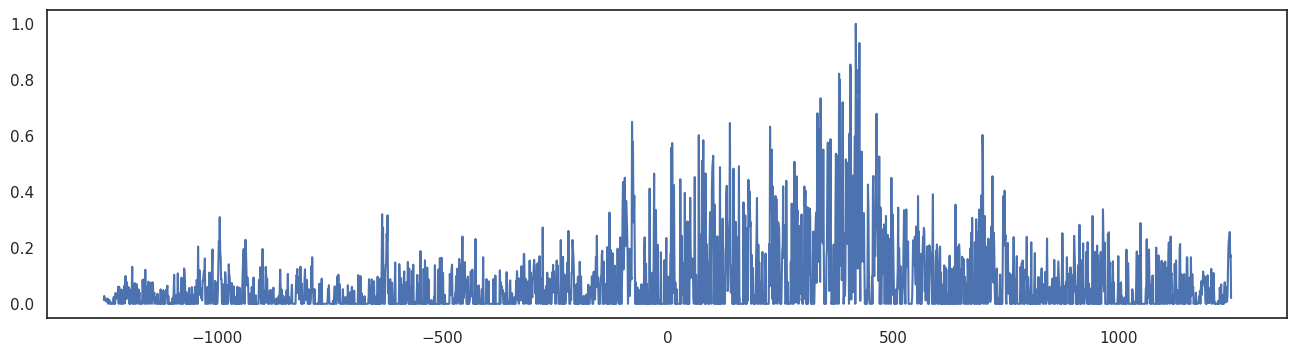

In [6]:
ism_values = (
    REGULATION_TYPE*(sum_lfc[:, :, exp_id] - sum_lfc[:, :, exp_id].mean(0))
    * hot_encode_sequence(ref_allele)
).max(axis=0)

important_positions = np.where(
    ism_values > MUTATION_THRESHOLD * ism_values.max()
)[0]-HALF

print("Most important positions are:")
print(important_positions)

plt.figure(figsize=(16,4))
plt.plot(np.arange(-HALF,HALF),ism_values/ism_values.max(),scaley=True)

# 7. TF Enrichment Analysis

In [7]:
treatment = gex_metadata.iloc[exp_id].Treatment
results_df = analyze_mutations_with_chip(
    gene=gene,
    sum_lfc=REGULATION_TYPE*sum_lfc[:,:,exp_id],
    ref_sequence=ref_allele,
    nuclt=nuclt,
    gene_df_full=gene_df,
    motif_dict=pssm_dict_jaspar,
    metadata=csp_metadata,
    bed_files_path=bed_files_path,
    mutation_threshold=MUTATION_THRESHOLD,
    score_threshold=MOTIF_SCORE_THRESHOLD,
    pad=20,
    seq_len=SEQ_LEN
)
csv_file_path = f"{gene_results_path}/results_{exp_id}.csv"
results_df.to_csv(csv_file_path,index=False)
print(f"Refer to the csv file at {csv_file_path} to see all mutations positions and TF enrichments")
loss_df = results_df.loc[
    (results_df.chip_peak_overlap == True) &
    (results_df.effect == 'Loss')
]
loss_df.head(10)

Refer to the csv file at /s/chromatin/m/nobackup/ahmed/GitRepositries/DeepPlant/results/ISM/AT4G25490/results_14.csv to see all mutations positions and TF enrichments


,gene,gene_strand,chromosome,tss_relative_position,gene_region,sequence_relative_position,genomic_position,ref,alt,motif,motif_strand,effect,chip_peak_overlap
6,AT4G25490,-1,Chr4,-95,promoter,1155,13023091,A,C,MA1182.2.RVE8,-1,Loss,True
8,AT4G25490,-1,Chr4,-95,promoter,1155,13023091,A,C,MA1184.2.RVE1,1,Loss,True
9,AT4G25490,-1,Chr4,-95,promoter,1155,13023091,A,C,MA1185.2.LHY,-1,Loss,True
10,AT4G25490,-1,Chr4,-95,promoter,1155,13023091,A,C,MA1187.2.RVE4,-1,Loss,True
13,AT4G25490,-1,Chr4,-95,promoter,1155,13023091,A,C,MA1401.2.RVE7,1,Loss,True
17,AT4G25490,-1,Chr4,-79,promoter,1171,13023075,G,C,MA0121.2.ARR10,1,Loss,True
19,AT4G25490,-1,Chr4,-78,promoter,1172,13023074,A,T,MA0121.2.ARR10,1,Loss,True
21,AT4G25490,-1,Chr4,-77,promoter,1173,13023073,T,A,MA0121.2.ARR10,1,Loss,True
124,AT4G25490,-1,Chr4,77,downstream,1327,13022919,G,A,MA1077.2.WRKY18,1,Loss,True
141,AT4G25490,-1,Chr4,77,downstream,1327,13022919,G,A,MA1794.2.NLP7,-1,Loss,True


# 8. Visualization

In [8]:
def create_track_ini(deep_plant_path: str, mutations_bed_path: str):
    """
    Creates a track.ini file for pyGenomeTracks at the specified deep_plant_path.
    """
    # Define the target directory and full file path
    directory = os.path.join(deep_plant_path, "results/pygenometracks/")
    file_path = os.path.join(directory, "track.ini")

    # Ensure the target directory exists
    create_path(path=directory)

    # Define the INI content, evaluating the deep_plant_path variable into the paths
    content = f"""[test bigwig1]
file = {deep_plant_path}/data/arabidopsis/bw/SRX3041700_Rep0.rpgc.bw
height = 2
title = OC(Leaf-NT)
min_value = 0
max_value = auto

[test bigwig2]
file = {deep_plant_path}/data/arabidopsis/bw/SRX7780579_Rep0.rpgc.bw
height = 2
title = OC(WP-Drought)
min_value = 0
max_value = auto

[test bigwig3]
file = {deep_plant_path}/data/arabidopsis/bw/SRX7780559_Rep0.rpgc.bw
height = 2
title = OC(WP-Cold)
min_value = 0
max_value = auto

[spacer]
height = 0.5

[genes]
file = {deep_plant_path}/data/arabidopsis/gtf/Arabidopsis.gtf
height = 4
style = flybase
display = stacked
color = #2F5D50
color_arrow = #1F3D36
arrow_interval = 50
fontsize = 12
labels = true
prefered_name = gene_id
merge_transcripts = true

[vlines]
file = {mutations_bed_path}
type = vlines
color = #C00000
alpha = 0.6
line_width = 2

[x-axis]
fontsize=10
"""

    # Write the content to the file
    with open(file_path, "w", encoding="utf-8") as f:
        f.write(content)

    print(f"Successfully created track.ini at: {file_path}")
    return file_path

Successfully created Zoom_in.bed at: /s/chromatin/m/nobackup/ahmed/GitRepositries/DeepPlant/results/pygenometracks/Zoom_in.bed
Successfully created track.ini at: /s/chromatin/m/nobackup/ahmed/GitRepositries/DeepPlant/results/pygenometracks/track.ini
Successfully created deep_plant_pathtrack__AT4G25490_14.pdf at: /s/chromatin/m/nobackup/ahmed/GitRepositries/DeepPlant/results/pygenometracks/deep_plant_pathtrack__AT4G25490_14.pdf
A mutation at position -95 relative to the gene TSS, A -> C causes the loss of the binding site of ['MA1182.2.RVE8', 'MA1184.2.RVE1', 'MA1185.2.LHY', 'MA1187.2.RVE4', 'MA1401.2.RVE7']
A mutation at position -79 relative to the gene TSS, G -> C causes the loss of the binding site of ['MA0121.2.ARR10']
A mutation at position -78 relative to the gene TSS, A -> T causes the loss of the binding site of ['MA0121.2.ARR10']
A mutation at position -77 relative to the gene TSS, T -> A causes the loss of the binding site of ['MA0121.2.ARR10']
A mutation at position 77 relat

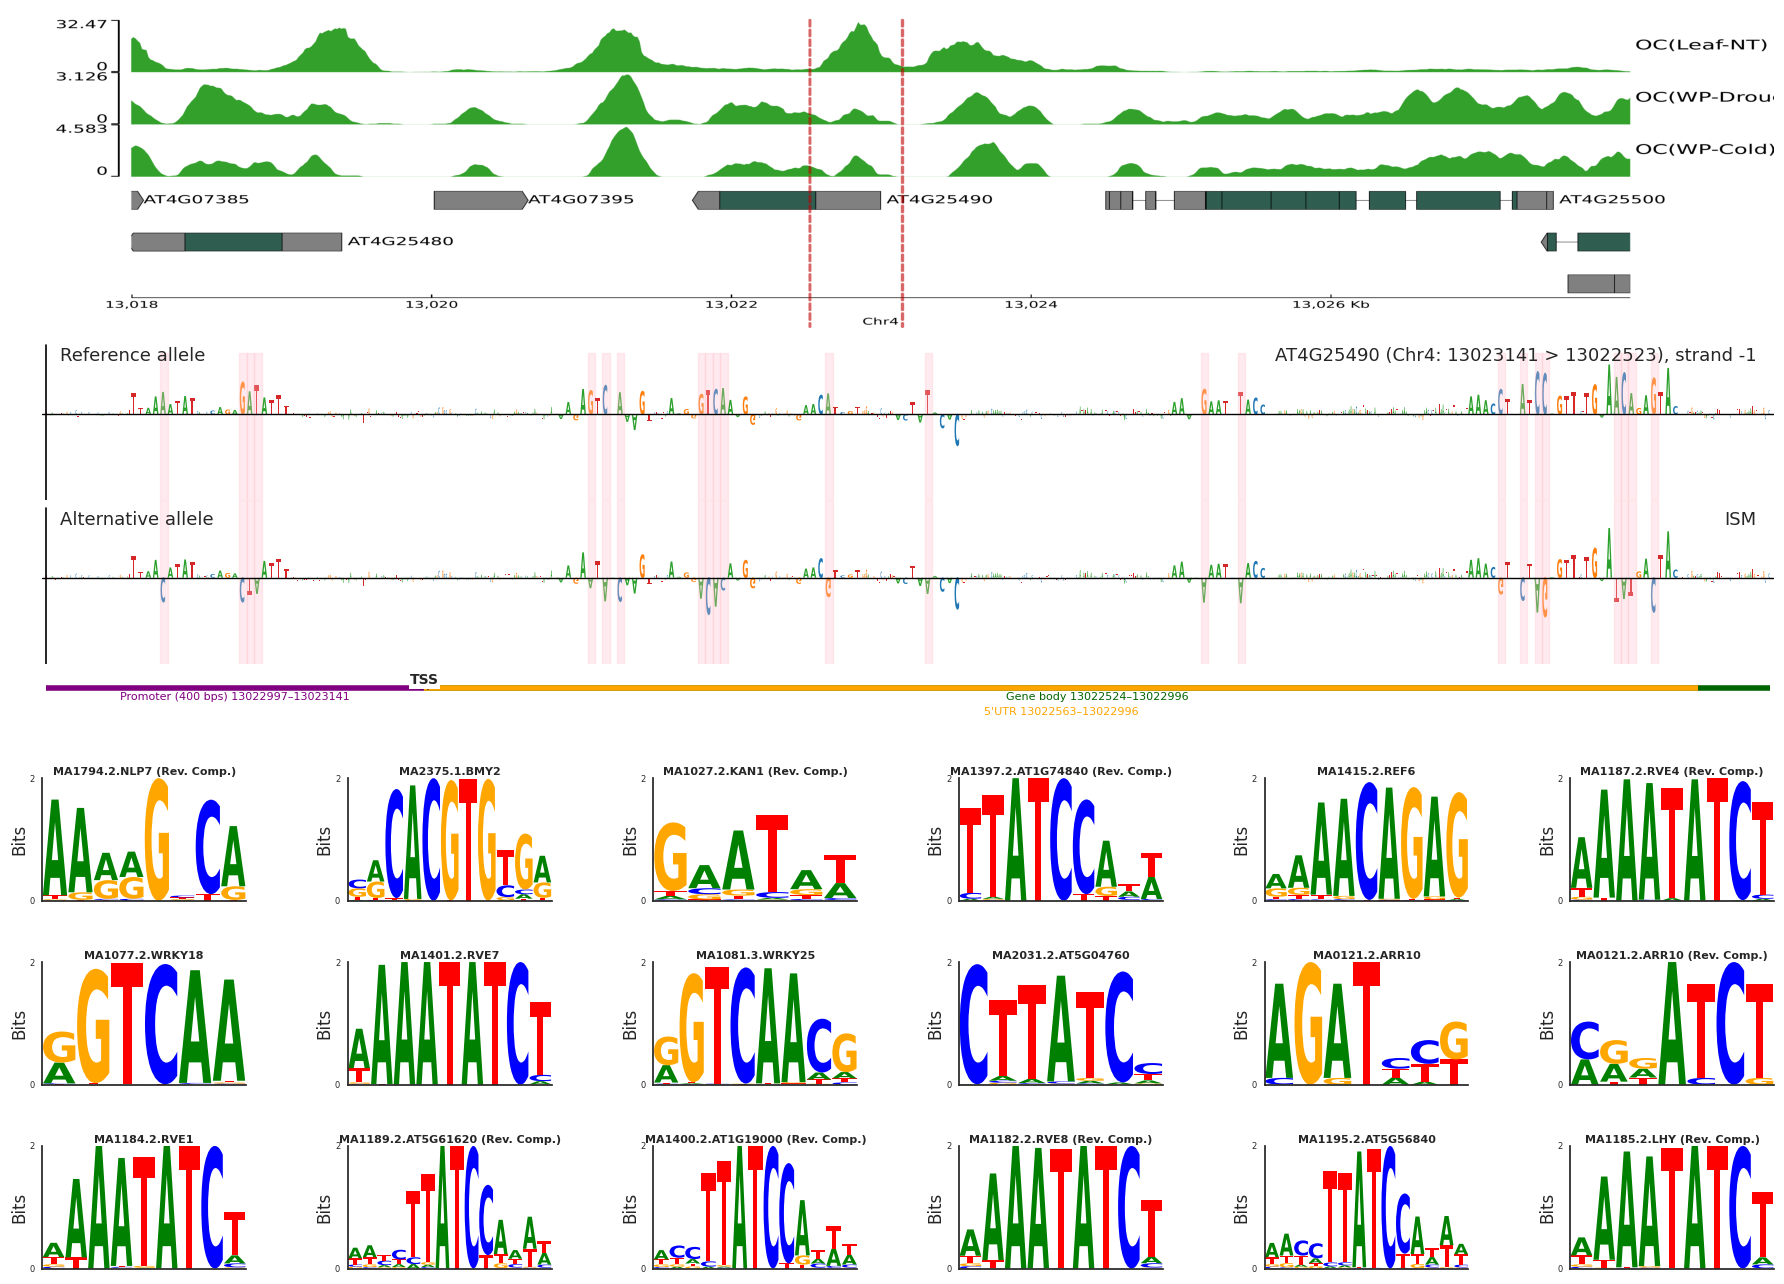

In [9]:
if loss_df.empty:
    print("No significant loss-of-function mutations supported by ChIP-seq data found.")
else:
    start = min(loss_df.sequence_relative_position.values.tolist())-50
    end = max(loss_df.sequence_relative_position.values.tolist())+50
    mutations_bed_path = create_zoom_in_bed(deep_plant_path,chrom,relative_to_genomic_position(start,tss,strand, SEQ_LEN//2),relative_to_genomic_position(end,tss,strand, SEQ_LEN//2))
    ini_file_path = create_track_ini(deep_plant_path, mutations_bed_path)
    region = f"Chr{chrom}:{int(tss)-5000}-{int(tss)+5000}"
    output_name = f"deep_plant_pathtrack__{gene}_{exp_id}.pdf"
    figure_path = os.path.join(deep_plant_path,f"results/pygenometracks/{output_name}")
    !pyGenomeTracks --tracks {ini_file_path} --region {region} --outFileName {figure_path} --dpi 500 --trackLabelFraction 0.0 > /dev/null 2>&1
    print(f"Successfully created {output_name} at: {figure_path}")
    plot_ref_alt_ism(
        figure_path=figure_path,
        gene=gene,
        chrom=f"Chr{chrom}",
        sum_lfc=REGULATION_TYPE*sum_lfc[:,:,exp_id],
        ref_sequence=ref_allele,
        results_df=loss_df,
        start = start,
        end = end,
        tss=tss,
        strand=strand,
        meme_path=meme_path,
        gff_db=gff_db_path,
        TSS_CENTER=SEQ_LEN//2,
        SEQ_LEN=SEQ_LEN
    )